# IMDb NLP Sentiment Classification



In [2]:
import os
import re
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from gensim.models import Word2Vec

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

DATA_PATH = "/content/IMDB Dataset.csv"
if not os.path.exists(DATA_PATH):
    DATA_PATH = r"C:\Users\ehabf\Downloads\archive (3)\IMDB Dataset.csv"

df = pd.read_csv(DATA_PATH)
df.head()


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [3]:
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())
print("\nClass distribution:")
print(df["sentiment"].value_counts())
print("\nSample reviews:")
display(df.sample(5, random_state=SEED))


Shape: (50000, 2)

Columns: ['review', 'sentiment']

Missing values:
review       0
sentiment    0
dtype: int64

Class distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Sample reviews:


,review,sentiment
33553,I really liked this Summerslam due to the look...,positive
9427,Not many television shows appeal to quite as m...,positive
199,The film quickly gets to a major chase scene w...,negative
12447,Jane Austen would definitely approve of this o...,positive
39489,Expectations were somewhat high for me when I ...,negative


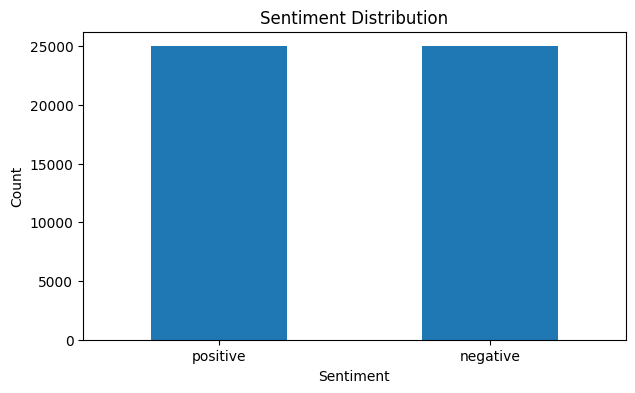

In [4]:
plt.figure(figsize=(7, 4))
df["sentiment"].value_counts().plot(kind="bar")
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()


## NLP Preprocessing

In [5]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<br\s*/?>", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"[^a-z0-9\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_review"] = df["review"].apply(clean_text)

sample_pre = df.sample(5, random_state=SEED)[["review", "clean_review", "sentiment"]]
display(sample_pre)


,review,clean_review,sentiment
33553,I really liked this Summerslam due to the look...,i really liked this summerslam due to the look...,positive
9427,Not many television shows appeal to quite as m...,not many television shows appeal to quite as m...,positive
199,The film quickly gets to a major chase scene w...,the film quickly gets to a major chase scene w...,negative
12447,Jane Austen would definitely approve of this o...,jane austen would definitely approve of this o...,positive
39489,Expectations were somewhat high for me when I ...,expectations were somewhat high for me when i ...,negative


In [6]:
tokenized_reviews = df["clean_review"].str.split()

print("Tokenized representations:")
for i, tokens in enumerate(tokenized_reviews.sample(2, random_state=SEED), 1):
    print(f"Review {i}:")
    print(tokens[:80])
    print()

lengths = tokenized_reviews.apply(len)
print("Average review length:", lengths.mean())
print("Maximum review length:", lengths.max())
print("Minimum review length:", lengths.min())


Tokenized representations:
Review 1:
['i', 'really', 'liked', 'this', 'summerslam', 'due', 'to', 'the', 'look', 'of', 'the', 'arena', 'the', 'curtains', 'and', 'just', 'the', 'look', 'overall', 'was', 'interesting', 'to', 'me', 'for', 'some', 'reason', 'anyways', 'this', 'could', 'have', 'been', 'one', 'of', 'the', 'best', "summerslam's", 'ever', 'if', 'the', 'wwf', "didn't", 'have', 'lex', 'luger', 'in', 'the', 'main', 'event', 'against', 'yokozuna', 'now', 'for', "it's", 'time', 'it', 'was', 'ok', 'to', 'have', 'a', 'huge', 'fat', 'man', 'vs', 'a', 'strong', 'man', 'but', "i'm", 'glad', 'times', 'have', 'changed', 'it', 'was', 'a', 'terrible', 'main', 'event', 'just']

Review 2:
['not', 'many', 'television', 'shows', 'appeal', 'to', 'quite', 'as', 'many', 'different', 'kinds', 'of', 'fans', 'like', 'farscape', 'does', 'i', 'know', 'youngsters', 'and', '30', '40', 'years', 'old', 'fans', 'both', 'male', 'and', 'female', 'in', 'as', 'many', 'different', 'countries', 'as', 'you', 'can',

## Train/Test Split

In [7]:
X = df["clean_review"]
y = (df["sentiment"] == "positive").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training class distribution:")
print(y_train.value_counts())


Training samples: 40000
Testing samples: 10000
Training class distribution:
sentiment
1    20000
0    20000
Name: count, dtype: int64


## Part B — TF-IDF Baseline

In [8]:
tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

tfidf_model = LogisticRegression(max_iter=1000, random_state=SEED)
tfidf_model.fit(X_train_tfidf, y_train)

tfidf_pred = tfidf_model.predict(X_test_tfidf)

tfidf_metrics = {
    "Model": "TF-IDF + Logistic Regression",
    "Representation": "TF-IDF",
    "Accuracy": accuracy_score(y_test, tfidf_pred),
    "Precision": precision_score(y_test, tfidf_pred),
    "Recall": recall_score(y_test, tfidf_pred),
    "F1": f1_score(y_test, tfidf_pred)
}

print(classification_report(y_test, tfidf_pred, target_names=["Negative", "Positive"]))


              precision    recall  f1-score   support

    Negative       0.91      0.90      0.91      5000
    Positive       0.90      0.91      0.91      5000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



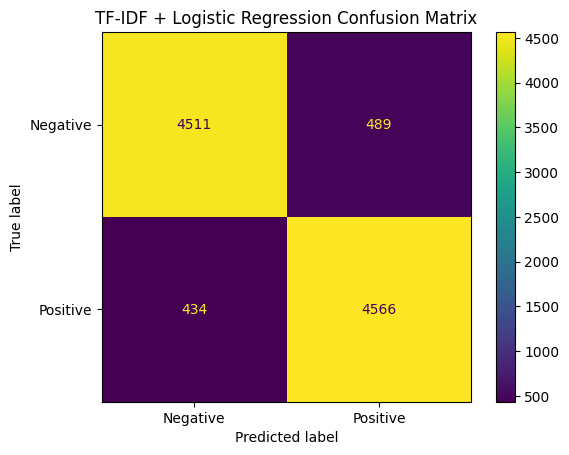

In [9]:
cm = confusion_matrix(y_test, tfidf_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative", "Positive"])
disp.plot()
plt.title("TF-IDF + Logistic Regression Confusion Matrix")
plt.show()


TF-IDF represents a document as a numerical vector based on word importance. Terms that occur frequently in one document but less frequently across the collection receive higher importance. The representation is usually sparse because each document contains only a small portion of the complete vocabulary. It is a strong classical baseline for text classification because it is simple, fast, and interpretable.

## TF-IDF Challenge — Feature and N-gram Experiment

In [10]:
tfidf_experiments = []

for max_features, ngram_range in [
    (10000, (1, 1)),
    (20000, (1, 1)),
    (20000, (1, 2)),
    (30000, (1, 2))
]:
    vec = TfidfVectorizer(
        max_features=max_features,
        ngram_range=ngram_range,
        sublinear_tf=True
    )
    tr = vec.fit_transform(X_train)
    te = vec.transform(X_test)
    model = LogisticRegression(max_iter=1000, random_state=SEED)
    model.fit(tr, y_train)
    pred = model.predict(te)
    tfidf_experiments.append({
        "max_features": max_features,
        "ngram_range": str(ngram_range),
        "Accuracy": accuracy_score(y_test, pred),
        "F1": f1_score(y_test, pred)
    })

tfidf_experiment_df = pd.DataFrame(tfidf_experiments)
display(tfidf_experiment_df)


,max_features,ngram_range,Accuracy,F1
0,10000,"(1, 1)",0.9007,0.901184
1,20000,"(1, 1)",0.9016,0.902167
2,20000,"(1, 2)",0.9077,0.908205
3,30000,"(1, 2)",0.9079,0.908567


## Part C — Word2Vec

In [11]:
train_tokens = [review.split() for review in X_train]

w2v = Word2Vec(
    sentences=train_tokens,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    epochs=10,
    seed=SEED
)

example_word = "movie"
if example_word in w2v.wv:
    print("Vector for movie:")
    print(w2v.wv[example_word])
else:
    example_word = list(w2v.wv.index_to_key)[0]
    print(f"Vector for {example_word}:")
    print(w2v.wv[example_word])

for word in ["movie", "good", "bad"]:
    if word in w2v.wv:
        print(f"\nMost similar to {word}:")
        print(w2v.wv.most_similar(word, topn=5))


Vector for movie:
[-3.3761927e-01  8.7011272e-01  2.3986251e+00 -2.1563652e+00
 -7.1266377e-01 -5.6277120e-01 -2.1168210e-02 -3.4680693e+00
  1.0879608e+00  1.4378325e+00  4.4741035e+00 -1.2116474e+00
 -5.4855871e-01 -2.1312642e+00  7.0650291e-01  1.7317287e+00
  7.9202078e-02  3.0269830e+00 -8.8634789e-01  3.6733689e+00
 -4.7667589e+00  2.5748951e+00 -2.9658613e+00  4.9724895e-01
  6.4468932e-01 -4.0476632e+00  1.4644377e+00  8.0996054e-01
 -2.3136177e+00 -6.3350117e-01  1.8307826e-01  4.7548118e-01
  3.3538482e-01  1.0860338e+00  1.0181162e+00  6.8074697e-01
 -2.7757745e+00  2.2862091e+00  1.5429152e+00 -2.3718850e-01
 -1.2342799e+00  1.3821920e+00 -2.7559352e+00 -1.6661987e+00
 -1.4427022e+00  2.2944036e+00  3.1734505e-01  5.8904606e-01
  6.4149505e-01 -1.3078678e+00  2.6336041e-01  8.6666113e-01
 -2.0438582e-01 -1.9238993e+00  1.0938321e-01 -1.2785892e+00
  1.8958834e+00 -3.3341202e-01  2.0745211e+00 -1.1749896e+00
 -3.2457351e-03 -1.5212100e+00 -8.8681787e-01 -8.7316549e-01
 -4.42

Word2Vec learns dense word representations from context. TF-IDF mainly measures term importance in documents, while Word2Vec learns relationships between words based on their surrounding context. As a result, Word2Vec vectors can capture semantic and contextual similarity between words.

## Neural Network Preparation

In [12]:
VOCAB_SIZE = 20000
MAX_LEN = 250

tokenizer = keras.preprocessing.text.Tokenizer(
    num_words=VOCAB_SIZE,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = keras.preprocessing.sequence.pad_sequences(
    X_train_seq, maxlen=MAX_LEN, padding="post", truncating="post"
)
X_test_pad = keras.preprocessing.sequence.pad_sequences(
    X_test_seq, maxlen=MAX_LEN, padding="post", truncating="post"
)

print(X_train_pad.shape)
print(X_test_pad.shape)


(40000, 250)
(10000, 250)


## Part D — Simple RNN

In [13]:
rnn_model = keras.Sequential([
    layers.Input(shape=(MAX_LEN,)),
    layers.Embedding(VOCAB_SIZE, 128),
    layers.SimpleRNN(64),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
])

rnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

rnn_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 250, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,574,465 (9.82 MB)

 Trainable params: 2,574,465 (9.82 MB)

 Non-trainable params: 0 (0.00 B)

In [14]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

rnn_history = rnn_model.fit(
    X_train_pad,
    y_train,
    validation_split=0.15,
    epochs=8,
    batch_size=128,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/8
266/266 ━━━━━━━━━━━━━━━━━━━━ 30s 105ms/step - accuracy: 0.5038 - loss: 0.6940 - val_accuracy: 0.4990 - val_loss: 0.6933
Epoch 2/8
266/266 ━━━━━━━━━━━━━━━━━━━━ 25s 95ms/step - accuracy: 0.5233 - loss: 0.6909 - val_accuracy: 0.5025 - val_loss: 0.6934
Epoch 3/8
266/266 ━━━━━━━━━━━━━━━━━━━━ 25s 96ms/step - accuracy: 0.5793 - loss: 0.6393 - val_accuracy: 0.5122 - val_loss: 0.7252


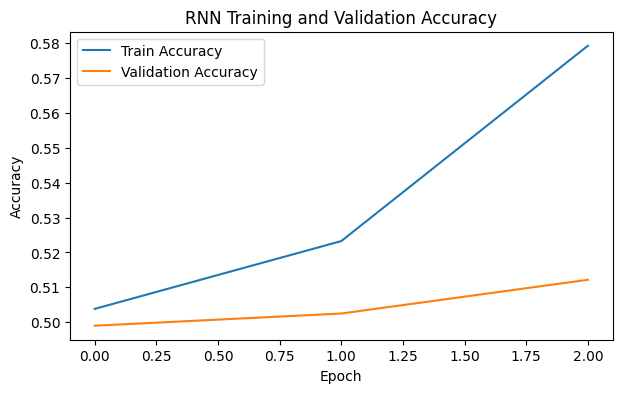

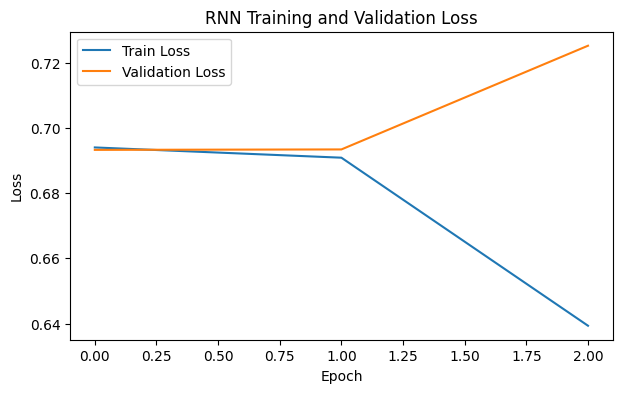

In [15]:
plt.figure(figsize=(7, 4))
plt.plot(rnn_history.history["accuracy"], label="Train Accuracy")
plt.plot(rnn_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("RNN Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(rnn_history.history["loss"], label="Train Loss")
plt.plot(rnn_history.history["val_loss"], label="Validation Loss")
plt.title("RNN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()


In [16]:
rnn_prob = rnn_model.predict(X_test_pad, batch_size=256, verbose=0).ravel()
rnn_pred = (rnn_prob >= 0.5).astype(int)

rnn_metrics = {
    "Model": "RNN",
    "Representation": "Embedding",
    "Accuracy": accuracy_score(y_test, rnn_pred),
    "Precision": precision_score(y_test, rnn_pred),
    "Recall": recall_score(y_test, rnn_pred),
    "F1": f1_score(y_test, rnn_pred)
}

print(classification_report(y_test, rnn_pred, target_names=["Negative", "Positive"]))


              precision    recall  f1-score   support

    Negative       0.50      0.99      0.66      5000
    Positive       0.52      0.01      0.02      5000

    accuracy                           0.50     10000
   macro avg       0.51      0.50      0.34     10000
weighted avg       0.51      0.50      0.34     10000



A basic RNN processes the sequence step by step and maintains a hidden state that carries information from earlier tokens. For long sequences, the basic recurrent structure can have difficulty preserving information over many time steps.

## Part E — LSTM

In [17]:
lstm_model = keras.Sequential([
    layers.Input(shape=(MAX_LEN,)),
    layers.Embedding(VOCAB_SIZE, 128),
    layers.LSTM(64),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
])

lstm_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

lstm_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 250, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,611,521 (9.96 MB)

 Trainable params: 2,611,521 (9.96 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
lstm_history = lstm_model.fit(
    X_train_pad,
    y_train,
    validation_split=0.15,
    epochs=8,
    batch_size=128,
    callbacks=[early_stop],
    verbose=1
)


Epoch 1/8
266/266 ━━━━━━━━━━━━━━━━━━━━ 156s 583ms/step - accuracy: 0.5185 - loss: 0.6926 - val_accuracy: 0.5517 - val_loss: 0.6774
Epoch 2/8
266/266 ━━━━━━━━━━━━━━━━━━━━ 51s 192ms/step - accuracy: 0.5575 - loss: 0.6691 - val_accuracy: 0.5397 - val_loss: 0.6789
Epoch 3/8
266/266 ━━━━━━━━━━━━━━━━━━━━ 46s 173ms/step - accuracy: 0.5894 - loss: 0.6348 - val_accuracy: 0.5603 - val_loss: 0.6740
Epoch 4/8
266/266 ━━━━━━━━━━━━━━━━━━━━ 45s 169ms/step - accuracy: 0.7639 - loss: 0.4961 - val_accuracy: 0.8348 - val_loss: 0.4159
Epoch 5/8
266/266 ━━━━━━━━━━━━━━━━━━━━ 48s 179ms/step - accuracy: 0.8891 - loss: 0.3085 - val_accuracy: 0.8413 - val_loss: 0.3838
Epoch 6/8
266/266 ━━━━━━━━━━━━━━━━━━━━ 51s 192ms/step - accuracy: 0.9314 - loss: 0.2145 - val_accuracy: 0.8667 - val_loss: 0.3588
Epoch 7/8
266/266 ━━━━━━━━━━━━━━━━━━━━ 52s 195ms/step - accuracy: 0.9439 - loss: 0.1793 - val_accuracy: 0.8648 - val_loss: 0.3951
Epoch 8/8
266/266 ━━━━━━━━━━━━━━━━━━━━ 52s 194ms/step - accuracy: 0.9584 - loss: 0.1410 -

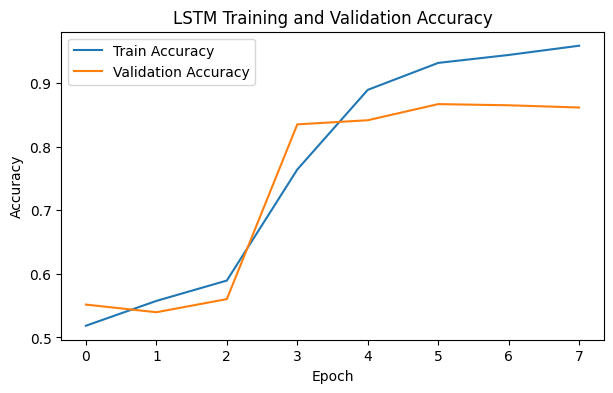

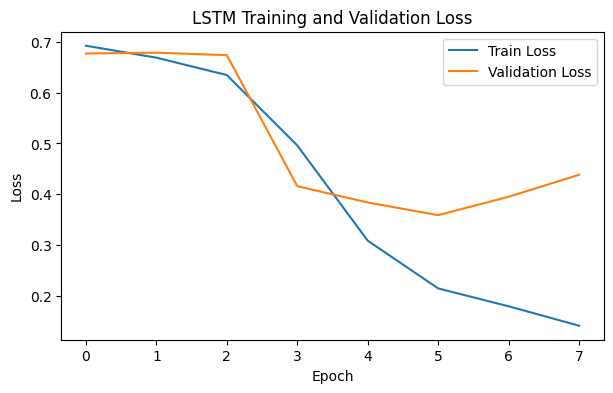

In [19]:
plt.figure(figsize=(7, 4))
plt.plot(lstm_history.history["accuracy"], label="Train Accuracy")
plt.plot(lstm_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("LSTM Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(lstm_history.history["loss"], label="Train Loss")
plt.plot(lstm_history.history["val_loss"], label="Validation Loss")
plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()


In [20]:
lstm_prob = lstm_model.predict(X_test_pad, batch_size=256, verbose=0).ravel()
lstm_pred = (lstm_prob >= 0.5).astype(int)

lstm_metrics = {
    "Model": "LSTM",
    "Representation": "Embedding",
    "Accuracy": accuracy_score(y_test, lstm_pred),
    "Precision": precision_score(y_test, lstm_pred),
    "Recall": recall_score(y_test, lstm_pred),
    "F1": f1_score(y_test, lstm_pred)
}

print(classification_report(y_test, lstm_pred, target_names=["Negative", "Positive"]))


              precision    recall  f1-score   support

    Negative       0.84      0.89      0.87      5000
    Positive       0.88      0.84      0.86      5000

    accuracy                           0.86     10000
   macro avg       0.86      0.86      0.86     10000
weighted avg       0.86      0.86      0.86     10000



LSTM extends the recurrent architecture with gates that control what information is retained, updated, and exposed. This helps it preserve useful information across longer dependencies than a basic RNN.

## Part F — Pretrained Transformer

In [21]:
try:
    from transformers import pipeline
    transformer_available = True
except Exception as e:
    transformer_available = False
    print("Transformers is not available in this environment.")


Transformers is not available in this environment.


In [22]:
transformer_results = pd.DataFrame()

if transformer_available:
    sentiment_pipeline = pipeline(
        "sentiment-analysis",
        model="distilbert-base-uncased-finetuned-sst-2-english"
    )

    transformer_reviews = df.sample(10, random_state=SEED)
    outputs = sentiment_pipeline(
        transformer_reviews["review"].tolist(),
        truncation=True,
        max_length=512
    )

    transformer_results = pd.DataFrame({
        "Review": transformer_reviews["review"].tolist(),
        "True Label": transformer_reviews["sentiment"].tolist(),
        "Prediction": [x["label"].lower() for x in outputs],
        "Score": [x["score"] for x in outputs]
    })

    transformer_results["Predicted Label"] = transformer_results["Prediction"].map({
        "positive": "positive",
        "negative": "negative"
    })

    transformer_results["Correct"] = (
        transformer_results["True Label"] == transformer_results["Predicted Label"]
    )

    display(transformer_results[[
        "True Label", "Predicted Label", "Score", "Correct", "Review"
    ]])
else:
    print("Install transformers and torch, then rerun this section.")


Install transformers and torch, then rerun this section.


A Transformer uses attention to determine which parts of a sequence are important when representing a token. Self-attention compares tokens within the same sequence. Query, Key, and Value vectors are used to calculate attention relationships. Positional information gives the model information about token order. Unlike an RNN, a Transformer does not process the sequence only through a single recurrent chain, allowing more parallel computation during training.

In [23]:
transformer_metrics = None

if transformer_available:
    transformer_metrics = {
        "Model": "Transformer",
        "Representation": "Contextual Embeddings",
        "Accuracy": transformer_results["Correct"].mean(),
        "Precision": precision_score(
            transformer_results["True Label"],
            transformer_results["Predicted Label"],
            pos_label="positive",
            zero_division=0
        ),
        "Recall": recall_score(
            transformer_results["True Label"],
            transformer_results["Predicted Label"],
            pos_label="positive",
            zero_division=0
        ),
        "F1": f1_score(
            transformer_results["True Label"],
            transformer_results["Predicted Label"],
            pos_label="positive",
            zero_division=0
        )
    }


## Model Comparison

In [24]:
comparison = pd.DataFrame([tfidf_metrics, rnn_metrics, lstm_metrics])

if transformer_metrics is not None:
    comparison = pd.concat(
        [comparison, pd.DataFrame([transformer_metrics])],
        ignore_index=True
    )

comparison


,Model,Representation,Accuracy,Precision,Recall,F1
0,TF-IDF + Logistic Regression,TF-IDF,0.9077,0.903264,0.9132,0.908205
1,RNN,Embedding,0.5004,0.522727,0.0092,0.018082
2,LSTM,Embedding,0.8632,0.884746,0.8352,0.859259


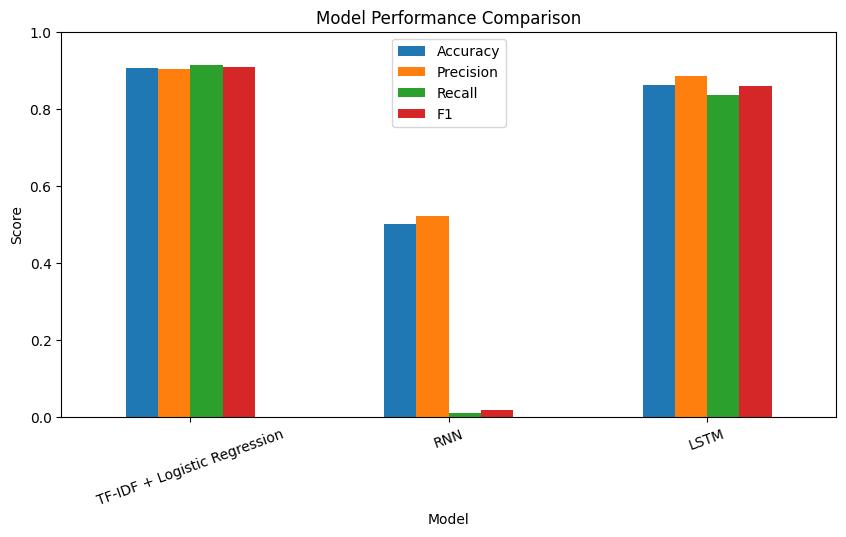

In [25]:
metric_columns = ["Accuracy", "Precision", "Recall", "F1"]

comparison.set_index("Model")[metric_columns].plot(
    kind="bar",
    figsize=(10, 5)
)
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend()
plt.show()


## Bonus 1 — Bidirectional LSTM

In [26]:
bilstm_model = keras.Sequential([
    layers.Input(shape=(MAX_LEN,)),
    layers.Embedding(VOCAB_SIZE, 128),
    layers.Bidirectional(layers.LSTM(64)),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(1, activation="sigmoid")
])

bilstm_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

bilstm_history = bilstm_model.fit(
    X_train_pad,
    y_train,
    validation_split=0.15,
    epochs=8,
    batch_size=128,
    callbacks=[early_stop],
    verbose=1
)

bilstm_prob = bilstm_model.predict(X_test_pad, batch_size=256, verbose=0).ravel()
bilstm_pred = (bilstm_prob >= 0.5).astype(int)

bilstm_metrics = {
    "Model": "Bidirectional LSTM",
    "Representation": "Embedding",
    "Accuracy": accuracy_score(y_test, bilstm_pred),
    "Precision": precision_score(y_test, bilstm_pred),
    "Recall": recall_score(y_test, bilstm_pred),
    "F1": f1_score(y_test, bilstm_pred)
}

bilstm_metrics


Epoch 1/8
266/266 ━━━━━━━━━━━━━━━━━━━━ 166s 612ms/step - accuracy: 0.7760 - loss: 0.4753 - val_accuracy: 0.8612 - val_loss: 0.3501
Epoch 2/8
266/266 ━━━━━━━━━━━━━━━━━━━━ 154s 579ms/step - accuracy: 0.9014 - loss: 0.2635 - val_accuracy: 0.8798 - val_loss: 0.3020
Epoch 3/8
266/266 ━━━━━━━━━━━━━━━━━━━━ 100s 376ms/step - accuracy: 0.9320 - loss: 0.1948 - val_accuracy: 0.8760 - val_loss: 0.3284
Epoch 4/8
266/266 ━━━━━━━━━━━━━━━━━━━━ 105s 396ms/step - accuracy: 0.9381 - loss: 0.1731 - val_accuracy: 0.8643 - val_loss: 0.3407


{'Model': 'Bidirectional LSTM',
 'Representation': 'Embedding',
 'Accuracy': 0.8746,
 'Precision': 0.9031424881618597,
 'Recall': 0.8392,
 'F1': 0.8699979266017002}

## Bonus 2 — Dropout Comparison

Epoch 1/5
266/266 ━━━━━━━━━━━━━━━━━━━━ 119s 414ms/step - accuracy: 0.7844 - loss: 0.4418 - val_accuracy: 0.8755 - val_loss: 0.3121
Epoch 2/5
266/266 ━━━━━━━━━━━━━━━━━━━━ 109s 408ms/step - accuracy: 0.9019 - loss: 0.2569 - val_accuracy: 0.8697 - val_loss: 0.3212
Epoch 3/5
266/266 ━━━━━━━━━━━━━━━━━━━━ 116s 438ms/step - accuracy: 0.9272 - loss: 0.1974 - val_accuracy: 0.8680 - val_loss: 0.3756
Epoch 4/5
266/266 ━━━━━━━━━━━━━━━━━━━━ 137s 418ms/step - accuracy: 0.9306 - loss: 0.1860 - val_accuracy: 0.8787 - val_loss: 0.3399
Epoch 5/5
266/266 ━━━━━━━━━━━━━━━━━━━━ 110s 415ms/step - accuracy: 0.9519 - loss: 0.1348 - val_accuracy: 0.8743 - val_loss: 0.3628


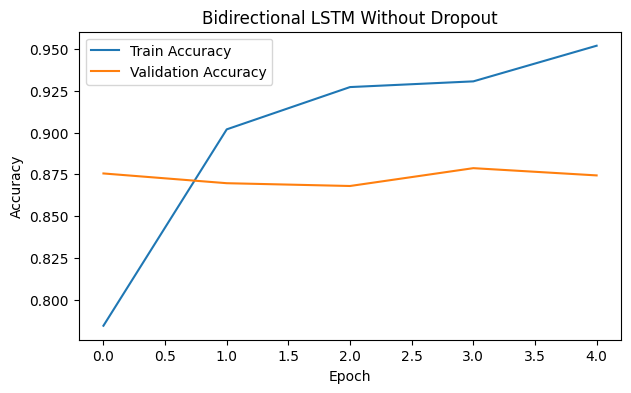

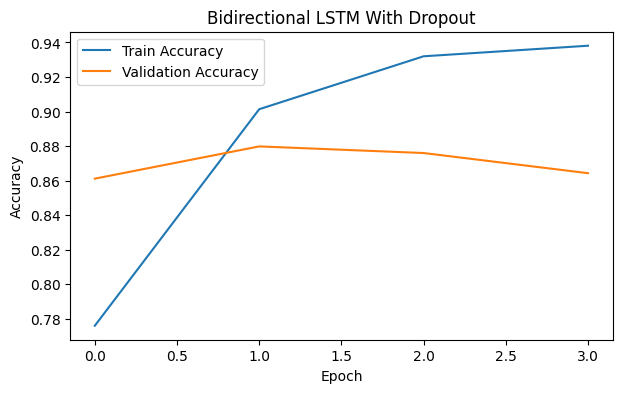

In [27]:
bilstm_no_dropout = keras.Sequential([
    layers.Input(shape=(MAX_LEN,)),
    layers.Embedding(VOCAB_SIZE, 128),
    layers.Bidirectional(layers.LSTM(64)),
    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

bilstm_no_dropout.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

no_dropout_history = bilstm_no_dropout.fit(
    X_train_pad,
    y_train,
    validation_split=0.15,
    epochs=5,
    batch_size=128,
    verbose=1
)

plt.figure(figsize=(7, 4))
plt.plot(no_dropout_history.history["accuracy"], label="Train Accuracy")
plt.plot(no_dropout_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Bidirectional LSTM Without Dropout")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(bilstm_history.history["accuracy"], label="Train Accuracy")
plt.plot(bilstm_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Bidirectional LSTM With Dropout")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


## Bonus 3 — GRU

In [28]:
gru_model = keras.Sequential([
    layers.Input(shape=(MAX_LEN,)),
    layers.Embedding(VOCAB_SIZE, 128),
    layers.GRU(64),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
])

gru_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

gru_history = gru_model.fit(
    X_train_pad,
    y_train,
    validation_split=0.15,
    epochs=8,
    batch_size=128,
    callbacks=[early_stop],
    verbose=1
)

gru_prob = gru_model.predict(X_test_pad, batch_size=256, verbose=0).ravel()
gru_pred = (gru_prob >= 0.5).astype(int)

gru_metrics = {
    "Model": "GRU",
    "Representation": "Embedding",
    "Accuracy": accuracy_score(y_test, gru_pred),
    "Precision": precision_score(y_test, gru_pred),
    "Recall": recall_score(y_test, gru_pred),
    "F1": f1_score(y_test, gru_pred)
}

gru_metrics


Epoch 1/8
266/266 ━━━━━━━━━━━━━━━━━━━━ 56s 201ms/step - accuracy: 0.5084 - loss: 0.6928 - val_accuracy: 0.5258 - val_loss: 0.6881
Epoch 2/8
266/266 ━━━━━━━━━━━━━━━━━━━━ 44s 166ms/step - accuracy: 0.5869 - loss: 0.6509 - val_accuracy: 0.7867 - val_loss: 0.5027
Epoch 3/8
266/266 ━━━━━━━━━━━━━━━━━━━━ 44s 164ms/step - accuracy: 0.8698 - loss: 0.3542 - val_accuracy: 0.8770 - val_loss: 0.3011
Epoch 4/8
266/266 ━━━━━━━━━━━━━━━━━━━━ 44s 166ms/step - accuracy: 0.9321 - loss: 0.2037 - val_accuracy: 0.8730 - val_loss: 0.3080
Epoch 5/8
266/266 ━━━━━━━━━━━━━━━━━━━━ 48s 180ms/step - accuracy: 0.9610 - loss: 0.1261 - val_accuracy: 0.8812 - val_loss: 0.3658


{'Model': 'GRU',
 'Representation': 'Embedding',
 'Accuracy': 0.8768,
 'Precision': 0.8854337152209493,
 'Recall': 0.8656,
 'F1': 0.8754045307443366}

## Bonus 4 — Vocabulary and Sequence Length Experiment

In [29]:
sequence_experiments = []

for vocab_size, max_len in [
    (10000, 150),
    (20000, 200),
    (20000, 250),
    (30000, 300)
]:
    temp_tokenizer = keras.preprocessing.text.Tokenizer(
        num_words=vocab_size,
        oov_token="<OOV>"
    )
    temp_tokenizer.fit_on_texts(X_train)

    tr_seq = temp_tokenizer.texts_to_sequences(X_train)
    te_seq = temp_tokenizer.texts_to_sequences(X_test)

    tr_pad = keras.preprocessing.sequence.pad_sequences(
        tr_seq, maxlen=max_len, padding="post", truncating="post"
    )
    te_pad = keras.preprocessing.sequence.pad_sequences(
        te_seq, maxlen=max_len, padding="post", truncating="post"
    )

    temp_model = keras.Sequential([
        layers.Input(shape=(max_len,)),
        layers.Embedding(vocab_size, 64),
        layers.GRU(32),
        layers.Dense(1, activation="sigmoid")
    ])

    temp_model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    temp_model.fit(
        tr_pad, y_train,
        validation_split=0.1,
        epochs=2,
        batch_size=256,
        verbose=0
    )

    temp_pred = (temp_model.predict(te_pad, batch_size=512, verbose=0).ravel() >= 0.5).astype(int)

    sequence_experiments.append({
        "Vocabulary Size": vocab_size,
        "Max Sequence Length": max_len,
        "Accuracy": accuracy_score(y_test, temp_pred),
        "F1": f1_score(y_test, temp_pred)
    })

sequence_experiment_df = pd.DataFrame(sequence_experiments)
display(sequence_experiment_df)


,Vocabulary Size,Max Sequence Length,Accuracy,F1
0,10000,150,0.8187,0.836002
1,20000,200,0.7725,0.786124
2,20000,250,0.5301,0.647196
3,30000,300,0.5462,0.299907


## Bonus 5 — Error Analysis

In [30]:
error_df = pd.DataFrame({
    "review": X_test.values,
    "true": y_test.values,
    "pred": lstm_pred
})

errors = error_df[error_df["true"] != error_df["pred"]].copy()

print("Number of LSTM errors:", len(errors))
display(errors.head(5))


Number of LSTM errors: 1368


,review,true,pred
13,interferencia starts as unemployed martin sand...,0,1
14,little quentin seems to have mastered the art ...,0,1
23,this movie is little more than poorly made fet...,0,1
24,not on the same level as ring or ring 2 but st...,1,0
25,this is not a great movie as tho the cast espe...,1,0


Common reasons for sentiment classification errors can include sarcasm, mixed sentiment, ambiguous language, negation, unusual vocabulary, and reviews containing both positive and negative opinions.

## Required Questions

### 1. What is NLP and why do computers need text preprocessing?

NLP is a field of artificial intelligence that enables computers to work with human language. Text preprocessing converts inconsistent raw language into a cleaner and more structured form that machine learning algorithms can process effectively.

### 2. What is the difference between a token, a sequence, and an embedding?

A token is a basic text unit such as a word. A sequence is an ordered collection of token IDs representing a piece of text. An embedding is a dense numerical vector used to represent a token or learned representation of text.

### 3. Why can raw text not be directly passed to most ML models?

Most traditional machine learning algorithms operate on numerical features rather than arbitrary strings. Text therefore needs to be converted into numerical representations such as TF-IDF vectors or embeddings.

### 4. What is the intuition behind TF-IDF?

TF-IDF increases the importance of terms that are frequent in a document but relatively uncommon across the collection. Very common terms across many documents receive lower importance.

### 5. Why does TF-IDF usually create sparse vectors?

The vocabulary may contain thousands of terms, but any individual review contains only a small subset of them. Most vector positions are therefore zero.

### 6. How is Word2Vec different from TF-IDF?

TF-IDF represents term importance using document-level statistics. Word2Vec learns dense vectors from word-context relationships and can capture semantic similarity between words.

### 7. What problem can a basic RNN face with long sequences?

A basic RNN can struggle to preserve information over long sequences because information may weaken as it passes through many recurrent steps. This is related to vanishing and exploding gradients.

### 8. What are the main components of an LSTM cell?

An LSTM contains a cell state and gates that control information flow, commonly described as the input gate, forget gate, and output gate.

### 9. Why does LSTM usually perform better than a basic RNN on long dependencies?

The LSTM cell state and gates provide a mechanism for retaining useful information over longer sequences and reducing the difficulty of learning long-term dependencies.

### 10. What is attention in a Transformer?

Attention allows the model to assign different importance to tokens when constructing a representation, allowing relationships between relevant parts of a sequence to be modeled directly.

### 11. Why does a Transformer not depend on recurrence in the same way as an RNN?

Transformers use attention rather than processing tokens through one recurrent hidden-state chain. This enables much more parallel computation during training.

### 12. Which model performed best in your experiment and why do you think it did?

The answer should be based on the final comparison table generated by this notebook. The strongest model is the one with the best evaluation results for the metric being prioritized. Contextual Transformer representations can be powerful because they represent words according to their surrounding context, while LSTM and RNN learn sequence representations from the training data.

### 13. Which model would you choose if computational resources were very limited?

TF-IDF with Logistic Regression is a strong choice because it is comparatively lightweight, fast to train, and does not require neural-network training.

### 14. What signs of overfitting did you observe, if any?

Overfitting can be identified when training accuracy continues increasing while validation accuracy stops improving or decreases, or when training loss decreases while validation loss increases. The training curves in this notebook should be inspected to make the conclusion based on the actual experiment.

## Final Conclusion

This project demonstrates a complete NLP sentiment-classification workflow using the IMDb movie-review dataset. The workflow begins with text cleaning, tokenization, sequence preparation, and exploratory inspection before moving to several different text representations and classification approaches. TF-IDF with Logistic Regression provides a strong classical baseline and offers a relatively efficient solution. Word2Vec demonstrates how dense word representations can capture relationships between words. RNN and LSTM models introduce neural sequence modeling, with LSTM providing mechanisms designed to preserve useful information across longer dependencies. A pretrained Transformer extends the comparison by using contextual representations and attention rather than recurrence. The bonus experiments further investigate Bidirectional LSTM, Dropout, GRU, vocabulary size, sequence length, and model errors. The final comparison should be based only on the metrics produced by the experiments. Overall, the project shows that model selection depends not only on predictive performance, but also on computational resources, training time, interpretability, and the characteristics of the NLP task.


## Final Results Including Bonus

In [31]:
final_results = pd.DataFrame([tfidf_metrics, rnn_metrics, lstm_metrics, bilstm_metrics, gru_metrics])

if transformer_metrics is not None:
    final_results = pd.concat(
        [final_results, pd.DataFrame([transformer_metrics])],
        ignore_index=True
    )

display(final_results.sort_values("F1", ascending=False).reset_index(drop=True))


,Model,Representation,Accuracy,Precision,Recall,F1
0,TF-IDF + Logistic Regression,TF-IDF,0.9077,0.903264,0.9132,0.908205
1,GRU,Embedding,0.8768,0.885434,0.8656,0.875405
2,Bidirectional LSTM,Embedding,0.8746,0.903142,0.8392,0.869998
3,LSTM,Embedding,0.8632,0.884746,0.8352,0.859259
4,RNN,Embedding,0.5004,0.522727,0.0092,0.018082


In [32]:
final_results.to_csv("IMDB_NLP_Final_Results.csv", index=False)
tfidf_experiment_df.to_csv("TFIDF_Experiments.csv", index=False)
sequence_experiment_df.to_csv("Sequence_Experiments.csv", index=False)

print("Result files saved.")


Result files saved.
